# 04 -- Dimensionality Reduction (PCA, t-SNE, UMAP)

This notebook implements and compares three dimensionality-reduction
techniques on the preprocessed, scaled expression matrix:

* **PCA** -- linear, variance-maximizing; scree plot, PC1-PC3, loadings.
* **t-SNE** -- non-linear, local-structure-preserving; compared across
  perplexity = 10, 30, 50.
* **UMAP** -- non-linear, faster and better at preserving some global
  structure than t-SNE; compared across `n_neighbors` and `min_dist`.


In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if (Path.cwd() / ".." / "src").exists() else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.config import load_config
from src.logging_config import setup_logging

setup_logging()
cfg = load_config(REPO_ROOT / "config.yaml")
FIGURES = REPO_ROOT / "figures"
RESULTS = REPO_ROOT / "results"
REPORTS = REPO_ROOT / "reports"
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
print(f"Repo root: {REPO_ROOT}")
print(f"Cancer type: {cfg['project']['cancer_type']}")


Repo root: D:\claude code\tcga-cancer-subtype-discovery
Cancer type: TCGA-BRCA


In [2]:
from src.preprocess import run_preprocessing
from src import clustering as cl
from src import visualization as viz

pp = run_preprocessing(cfg)
scaled_expr = pp["scaled_expr"]
clinical = pp["clinical"]
has_truth = "true_subtype" in clinical.columns
truth = clinical["true_subtype"] if has_truth else None
dr_cfg = cfg["dimensionality_reduction"]


2026-07-28 15:05:52 | INFO     | src.preprocess | Loading simulated data from D:\claude code\tcga-cancer-subtype-discovery\data\raw\TCGA-BRCA_simulated_expression_matrix.tsv


2026-07-28 15:05:52 | INFO     | src.preprocess | QC: 4000 genes x 500 samples | 0.1028% missing | median library size 880248 | median genes detected 3980


2026-07-28 15:05:52 | INFO     | src.preprocess | Imputing 2056 missing values with per-gene median.


2026-07-28 15:05:52 | INFO     | src.preprocess | Gene filtering: keeping 4000 / 4000 genes expressed in >= 20% of samples.


2026-07-28 15:05:52 | INFO     | src.preprocess | Outlier detection: flagged 11 / 500 samples (robust z > 3.5).


2026-07-28 15:05:53 | INFO     | src.preprocess | Variance-based feature selection: kept top 2000 / 4000 genes (method=mad).


2026-07-28 15:05:56 | INFO     | src.preprocess | Preprocessing complete. Summary: {'n_genes_raw': 4000, 'n_samples_raw': 500, 'pct_missing_raw': 0.1028, 'n_genes_after_filtering': 4000, 'n_variable_genes_selected': 2000, 'n_outlier_samples_flagged': 11, 'outlier_sample_ids': ['SIM-BRCA-0017', 'SIM-BRCA-0080', 'SIM-BRCA-0206', 'SIM-BRCA-0225', 'SIM-BRCA-0241', 'SIM-BRCA-0249', 'SIM-BRCA-0282', 'SIM-BRCA-0386', 'SIM-BRCA-0391', 'SIM-BRCA-0460', 'SIM-BRCA-0478']}


## 4.1 PCA

### Scree plot and cumulative explained variance

PC1 explains 14.30% of variance; top 10 PCs explain 41.91%


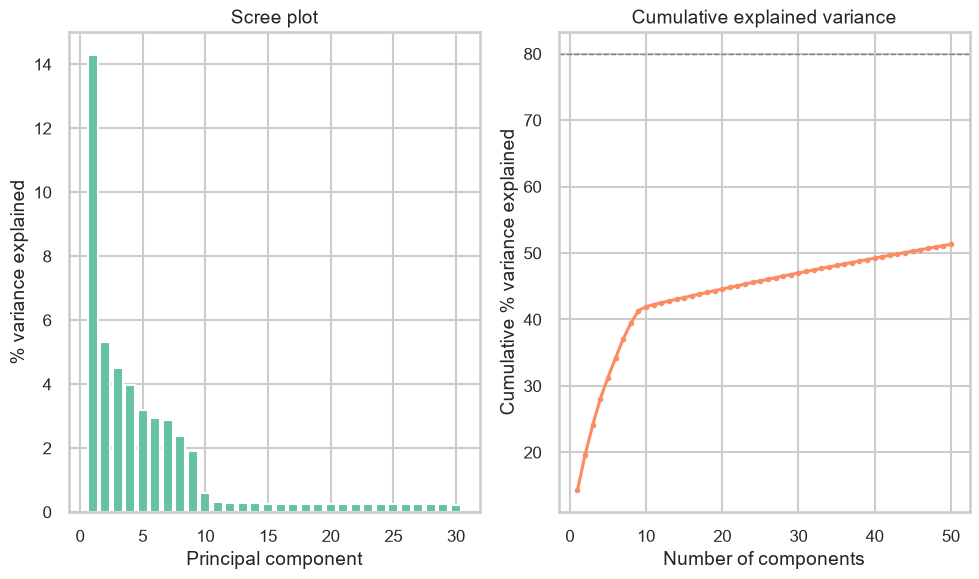

In [3]:
pca_result = cl.run_pca(scaled_expr, n_components=dr_cfg["pca"]["n_components"])
scores, loadings, evr = pca_result["scores"], pca_result["loadings"], pca_result["explained_variance_ratio"]
print(f"PC1 explains {evr[0]*100:.2f}% of variance; top 10 PCs explain {evr[:10].sum()*100:.2f}%")
fig = viz.plot_scree(evr, save_path=FIGURES / "dimensionality_reduction" / "pca_scree.png")


### PC1 vs PC2 and PC1 vs PC3

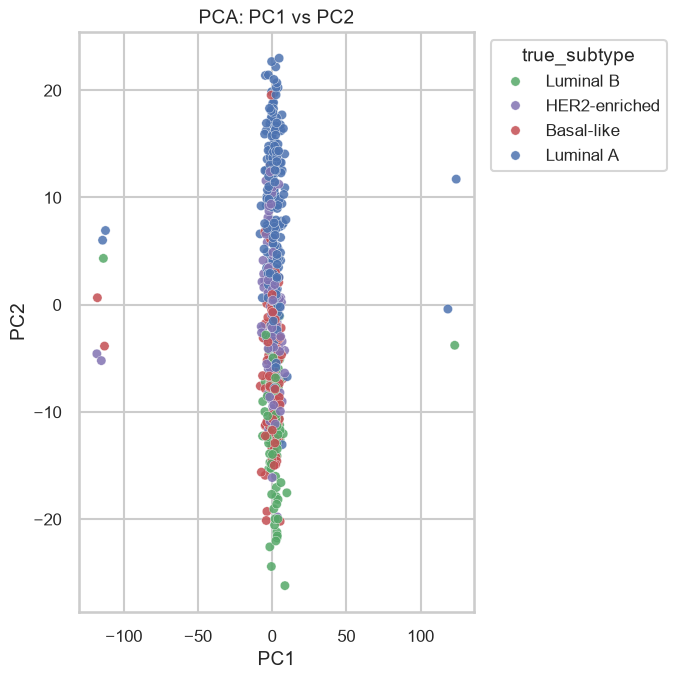

In [4]:
fig = viz.plot_pc_scatter(scores, "PC1", "PC2", hue=truth, title="PCA: PC1 vs PC2", palette=viz.SUBTYPE_PALETTE)


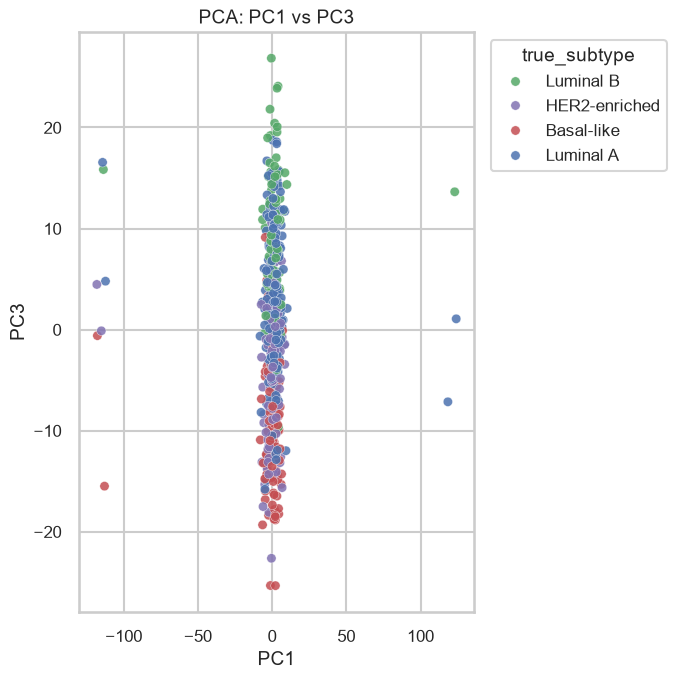

In [5]:
fig = viz.plot_pc_scatter(scores, "PC1", "PC3", hue=truth, title="PCA: PC1 vs PC3", palette=viz.SUBTYPE_PALETTE)


**Reading this plot honestly.** PC1 in this cohort is dominated by a small
number of extreme outlier samples (the globally-scaled outliers flagged in
notebook 02) plus a subtype-independent latent program (the simulator
includes several subtype-*unrelated* co-expression programs representing
realistic nuisance biological variation, e.g. immune infiltration). The
intrinsic-subtype signal concentrates in PC2-PC4 instead (see the ANOVA
below). This is a genuine and important lesson: **the axis of greatest
overall variance is not always the axis of greatest biological/clinical
relevance** -- a well-known pitfall when naively using only PC1/PC2 for
interpretation. It is why we also inspect loadings, later PCs, t-SNE, UMAP,
and supervised differential expression rather than stopping at "PC1 vs PC2 look separated or not".

In [6]:
from scipy import stats
for pc in ["PC1", "PC2", "PC3", "PC4"]:
    if truth is not None:
        groups = [scores.loc[truth == s, pc].values for s in truth.unique()]
        f_stat, p_val = stats.f_oneway(*groups)
        print(f"{pc}: F={f_stat:8.2f}  p={p_val:.2e}  {'<-- strong subtype association' if p_val < 1e-6 else ''}")


PC1: F=    1.44  p=2.30e-01  
PC2: F=  231.36  p=7.42e-94  <-- strong subtype association
PC3: F=  165.22  p=3.03e-74  <-- strong subtype association
PC4: F=  182.79  p=8.24e-80  <-- strong subtype association


### PCA loadings: which genes drive each axis?

In [7]:
top_pc1 = cl.top_pc_loadings(loadings, "PC1", top_n=15)
top_pc2 = cl.top_pc_loadings(loadings, "PC2", top_n=15)
display(top_pc1)
display(top_pc2)


,PC1_loading
gene_name,
TAS2R20,0.031903
OR13C8,0.031334
BTG3,0.030952
CNGA2,0.030739
ADCYAP1R1,0.030731
HOMER1,0.030648
FOXO3,0.030565
GYS2,0.030480
URM1,0.030367


,PC2_loading
gene_name,
NPFFR1,0.088413
RBM22,-0.082770
KLF5,0.078722
CD38,0.078545
IRF7,0.077827
EXTL2,0.072602
CD37,-0.072279
RIMS2,-0.071928
CHRNB1,0.071858


## 4.2 t-SNE across perplexity values

In [8]:
tsne_embeddings = {}
for perplexity in dr_cfg["tsne"]["perplexities"]:
    tsne_embeddings[f"perplexity={perplexity}"] = cl.run_tsne(scaled_expr, perplexity=perplexity)
    print(f"t-SNE perplexity={perplexity} done.")


t-SNE perplexity=10 done.


t-SNE perplexity=30 done.


t-SNE perplexity=50 done.


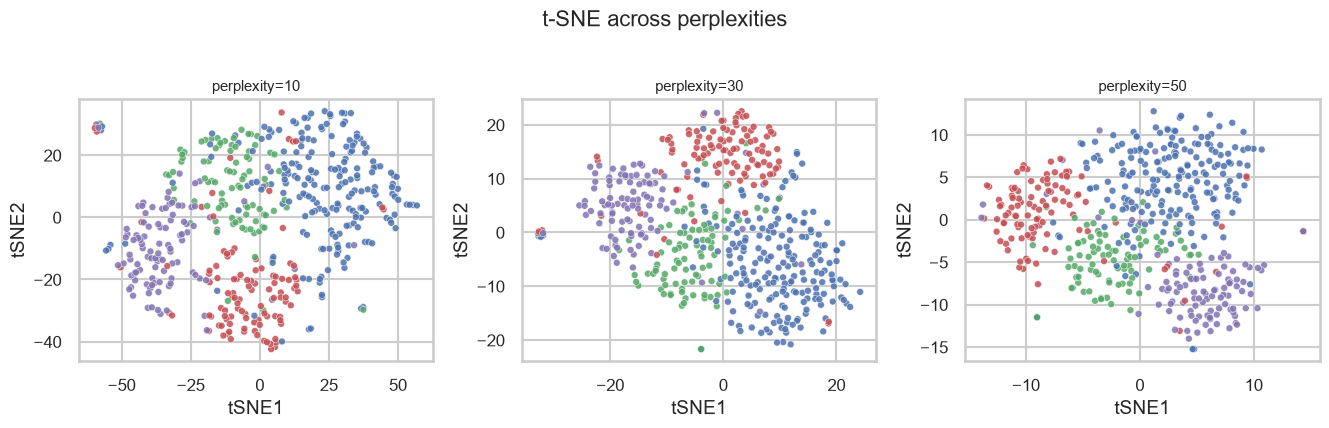

In [9]:
if truth is not None:
    fig = viz.plot_embedding_grid(tsne_embeddings, truth, title="t-SNE across perplexities", palette=viz.SUBTYPE_PALETTE)


**Perplexity discussion.** Low perplexity (10) emphasizes fine local
neighborhoods and can fragment a true cluster into several visual
sub-islands; high perplexity (50) smooths those fine distinctions out and
better reflects the global 4-group structure but can also blur boundaries
between genuinely similar subtypes (Luminal A/B). Perplexity 30 (the
common default, roughly `sqrt(n_samples)`-scaled) is a reasonable
middle ground for this cohort size.

## 4.3 UMAP across n_neighbors and min_dist

In [10]:
umap_embeddings = {}
for n_neighbors in dr_cfg["umap"]["n_neighbors_grid"]:
    umap_embeddings[f"n_neighbors={n_neighbors}"] = cl.run_umap(
        scaled_expr, n_neighbors=n_neighbors, min_dist=dr_cfg["umap"]["default_min_dist"]
    )
    print(f"UMAP n_neighbors={n_neighbors} done.")


UMAP n_neighbors=5 done.


UMAP n_neighbors=15 done.


UMAP n_neighbors=30 done.


UMAP n_neighbors=50 done.


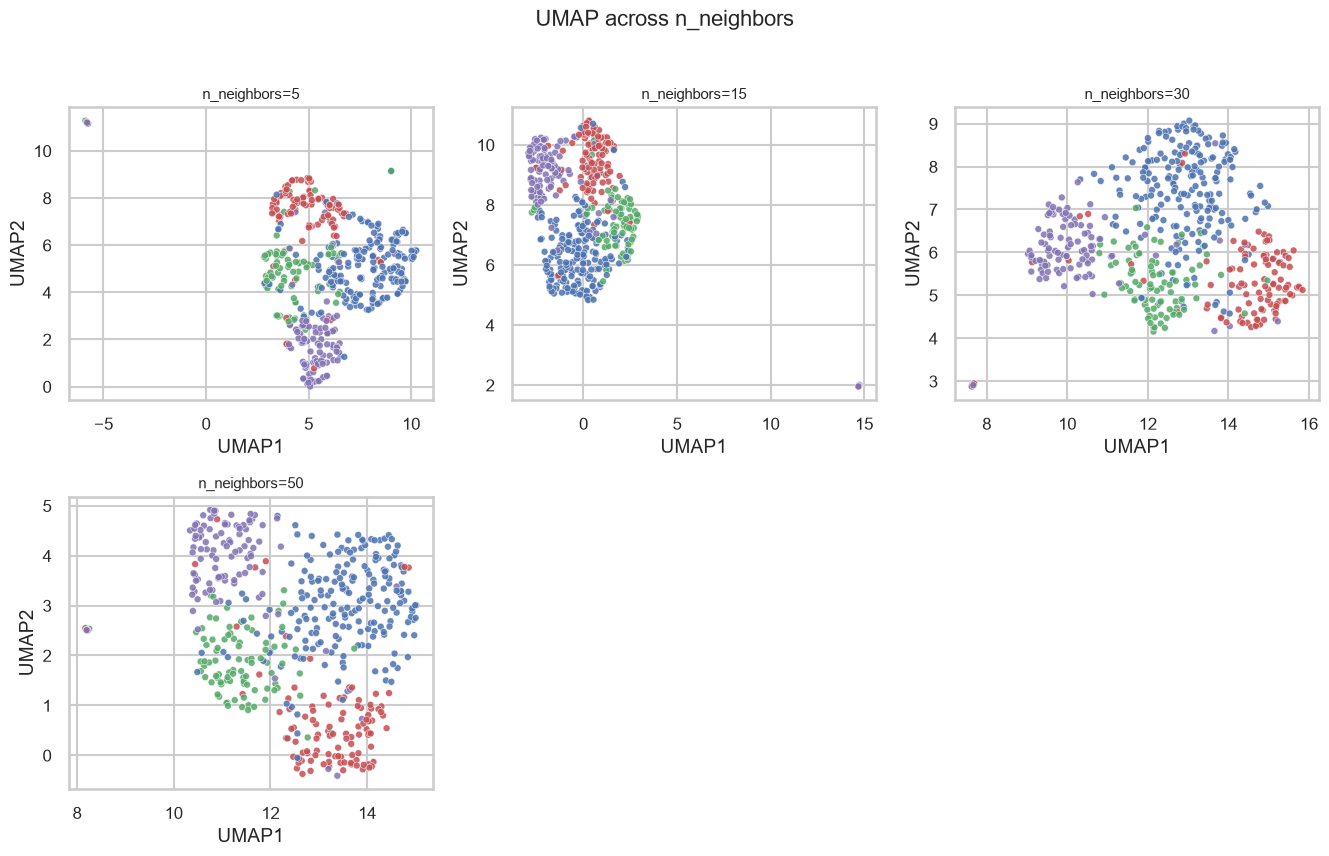

In [11]:
if truth is not None:
    fig = viz.plot_embedding_grid(umap_embeddings, truth, title="UMAP across n_neighbors", palette=viz.SUBTYPE_PALETTE)


In [12]:
min_dist_embeddings = {}
for min_dist in dr_cfg["umap"]["min_dist_grid"]:
    min_dist_embeddings[f"min_dist={min_dist}"] = cl.run_umap(
        scaled_expr, n_neighbors=dr_cfg["umap"]["default_n_neighbors"], min_dist=min_dist
    )
    print(f"UMAP min_dist={min_dist} done.")


UMAP min_dist=0.0 done.


UMAP min_dist=0.1 done.


UMAP min_dist=0.25 done.


UMAP min_dist=0.5 done.


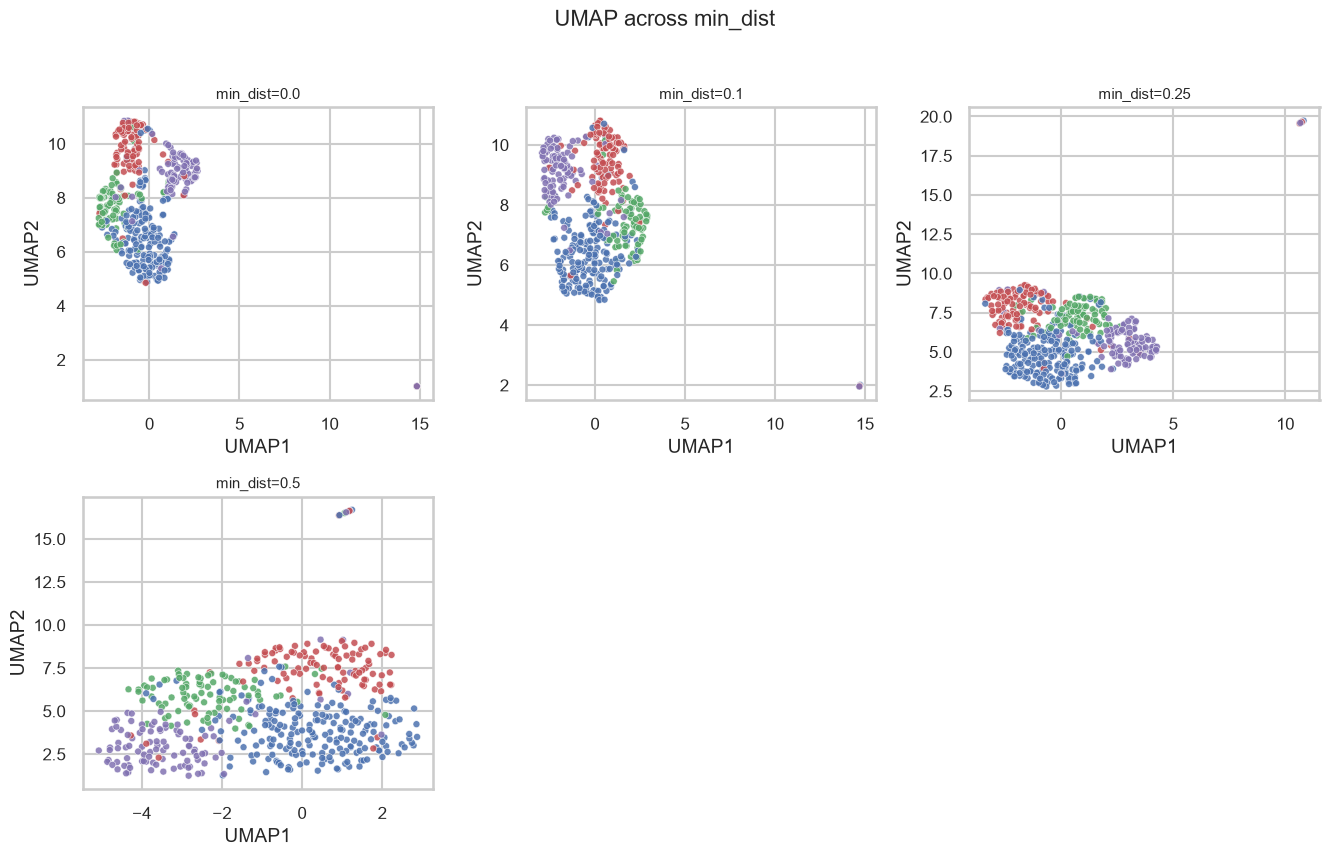

In [13]:
if truth is not None:
    fig = viz.plot_embedding_grid(min_dist_embeddings, truth, title="UMAP across min_dist", palette=viz.SUBTYPE_PALETTE)


**UMAP hyperparameter discussion.**
* `n_neighbors` controls the local/global trade-off: small values (5) chase
  fine local structure (more, smaller fragments); large values (50) favor
  the global manifold shape at the expense of fine detail.
* `min_dist` controls how tightly points are packed in the embedding: 0.0
  produces tight, well-separated clumps (good for visually confirming
  discrete clusters); larger values (0.5) spread points into a more
  continuous manifold (better for visualizing a trajectory / continuum,
  which is arguably closer to the biological reality of a continuum of
  hormone-receptor signaling activity rather than four hard boxes).
* **Biological interpretation**: UMAP's preservation of some global
  distances (unlike t-SNE) makes the *relative* positioning of clusters
  more trustworthy -- e.g. Luminal A and Luminal B typically sit closer to
  each other than either does to Basal-like, mirroring their shared
  ER-positive biology.

## 4.4 Default UMAP embedding (used downstream for visual QC of clusters)

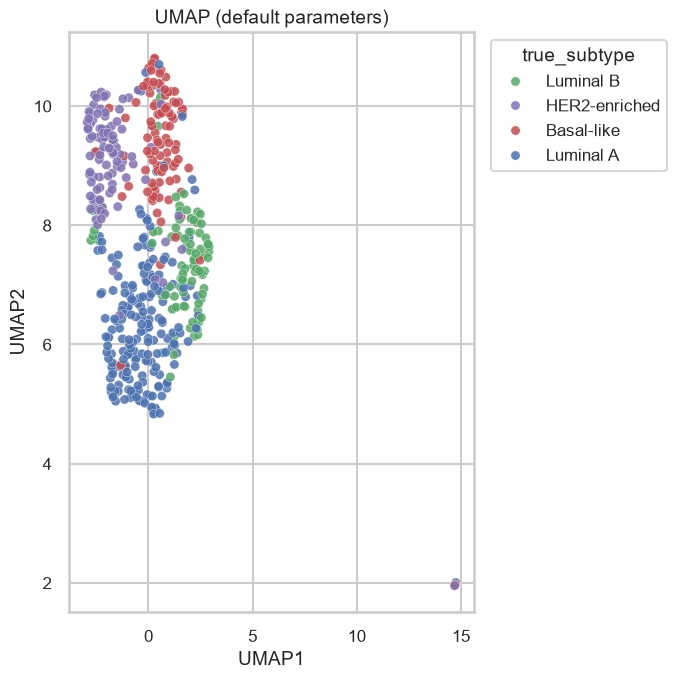

In [14]:
default_umap = umap_embeddings.get(f"n_neighbors={dr_cfg['umap']['default_n_neighbors']}")
if default_umap is None:
    default_umap = cl.run_umap(scaled_expr, n_neighbors=dr_cfg["umap"]["default_n_neighbors"], min_dist=dr_cfg["umap"]["default_min_dist"])
fig = viz.plot_pc_scatter(default_umap, "UMAP1", "UMAP2", hue=truth, title="UMAP (default parameters)", palette=viz.SUBTYPE_PALETTE)


## Summary

* PCA's leading axis (PC1) is dominated by outliers/nuisance variation in
  this cohort, not subtype -- a reminder to check loadings and multiple PCs
  rather than assuming PC1/PC2 tell the whole story.
* t-SNE and UMAP, given a suitable hyperparameter choice, visually recover
  4 groups broadly consistent with the known PAM50-like subtypes, with
  Luminal A/B sitting closer together than to Basal-like or HER2-enriched --
  consistent with their shared ER-pathway biology.
* These 2-D embeddings are for **visualization and QC only**; the
  quantitative clustering in notebook 05 is performed on the full
  scaled expression matrix (and, for density-based methods, a 30-component
  PCA embedding), not on the 2-D t-SNE/UMAP coordinates.